# 01 · Limpieza completa y EDA

**Jorge Javier Palma Martínez · ML1 FIUNA · 2026**

Protocolo: `rectangular-masked-v3-2026-11-22`.

Se parte de 1.650 imágenes. Se excluyen 68 copias exactas y 6 imágenes contradictorias; quedan 1.576. La limpieza conserva `data/raw/Training` y materializa `data/clean/Training` antes de dividir.

Este cuaderno contiene el código ejecutable de la etapa, dividido en celdas con explicación. Ejecutar de arriba hacia abajo. Los notebooks se recorren del 01 al 06; los ajustes y las curvas pueden tardar varios minutos.

## 1. Librerías y ubicación del proyecto

Se cargan las bibliotecas utilizadas y se localiza la carpeta raíz. La misma celda funciona al abrir el notebook desde la raíz o desde `notebooks`. No entrena ningún modelo.

In [ ]:
from pathlib import Path
import sys, json, hashlib, shutil, time, warnings, copy
import numpy as np
import pandas as pd
import cv2
import joblib
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/workflow.py").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from sklearn.model_selection import train_test_split


## 2. Configuración y carpetas de salida

Se fija la semilla, el orden de las cinco etiquetas y las rutas de matrices, informes y modelos. Crear estas carpetas no modifica las radiografías originales.

In [ ]:
DATA = ROOT / "data/processed"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
MODELS = ROOT / "models"
LABELS = ["Normal", "Dudosa", "Leve", "Moderada", "Severa"]
SEED = 42
PROTOCOL = "rectangular-masked-v3-2026-11-22"
for folder in [DATA, REPORTS, FIGURES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
print("Proyecto:", ROOT)
print("Protocolo:", PROTOCOL)


Proyecto: <proyecto-rodilla>
Protocolo: rectangular-masked-v3-2026-11-22


## 3. Guardar resultados y mostrar las figuras

La primera función exporta JSON evitando NaN/Infinity. La segunda guarda cada gráfico y lo muestra dentro del notebook, para que el documento conserve código y salida al verse en GitHub.

In [ ]:
def save_json(path, value):
    def finite(item):
        if isinstance(item, dict):
            return {k: finite(v) for k, v in item.items()}
        if isinstance(item, (list, tuple)):
            return [finite(v) for v in item]
        if isinstance(item, np.generic):
            item = item.item()
        if isinstance(item, float) and not np.isfinite(item):
            return None
        return item

    Path(path).write_text(
        json.dumps(
            finite(value), ensure_ascii=False, indent=2, allow_nan=False, default=str
        ),
        encoding="utf-8",
    )


def figure(name):
    path = FIGURES / name
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.close()
    display(Image(filename=str(path)))


## 4. Identidad de una imagen: hash de forma y píxeles

SHA-256 se calcula sobre la imagen decodificada, no sobre el nombre o la compresión del archivo. Esto detecta igualdad exacta; no detecta todos los recortes o casi duplicados.

In [ ]:
def pixel_digest(image):
    return hashlib.sha256(str(image.shape).encode() + image.tobytes()).hexdigest()


## 5. Recorrer originales y decidir inclusiones

Se muestra el algoritmo completo: lectura en gris, inventario, grupos con más de una etiqueta, exclusión completa de conflictos y conservación de una sola copia cuando las etiquetas coinciden.

In [ ]:
def audit_dataset(project_root):
    root = Path(project_root)
    rows = []
    for p in sorted((root / "data/raw/Training").rglob("*")):
        if p.suffix.lower() not in {".png", ".jpg", ".jpeg"}:
            continue
        image = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
        if image is None:
            raise ValueError(f"Imagen ilegible: {p}")
        target = int(p.parent.name[0])
        h, w = image.shape
        rows.append(
            dict(
                path=p.relative_to(root).as_posix(),
                class_name=p.parent.name,
                class_label=LABELS[target],
                target=target,
                width=w,
                height=h,
                resolution=f"{w} x {h}",
                pixel_sha256=pixel_digest(image),
            )
        )
    df = pd.DataFrame(rows)
    if df.empty:
        raise FileNotFoundError("Colocá el dataset en data/raw/Training/<clase>/*.png")
    conflicts = df.groupby("pixel_sha256").target.nunique()
    bad = set(conflicts[conflicts > 1].index)
    df["audit_status"] = "included"
    df.loc[df.pixel_sha256.isin(bad), "audit_status"] = "conflicting_label"
    eligible = df[~df.pixel_sha256.isin(bad)]
    df.loc[
        eligible.index[eligible.duplicated("pixel_sha256", keep="first")],
        "audit_status",
    ] = "duplicate_copy"
    canonical = (
        df[df.audit_status == "included"].set_index("pixel_sha256").path.to_dict()
    )
    df["canonical_path"] = df.pixel_sha256.map(canonical).fillna("")
    return df


## 6. Construir una copia limpia sin borrar originales

La función copia únicamente las imágenes aceptadas, usa nombres basados en hashes y comprueba que una segunda ejecución no genere copias adicionales. Guarda la relación entre archivo original y copia limpia.

In [ ]:
def materialize_clean_dataset(inventory, project_root):
    """Create only accepted files, named by pixel hash. Raw files are read-only."""
    root = Path(project_root).resolve()
    destination = root / "data/clean/Training"
    rows = []
    for record in inventory[inventory.audit_status == "included"].itertuples():
        source = root / record.path
        target = (
            destination
            / record.class_name
            / (record.pixel_sha256 + source.suffix.lower())
        )
        target.parent.mkdir(parents=True, exist_ok=True)
        if target.exists():
            existing = cv2.imread(str(target), 0)
            if existing is None or pixel_digest(existing) != record.pixel_sha256:
                raise ValueError(f"La copia limpia no coincide: {target}")
        else:
            shutil.copy2(source, target)
        rows.append(
            dict(
                original_path=record.path,
                clean_path=target.relative_to(root).as_posix(),
                target=record.target,
                class_name=record.class_name,
                pixel_sha256=record.pixel_sha256,
            )
        )
    clean = pd.DataFrame(rows)
    expected = set(clean.clean_path)
    actual = {
        p.relative_to(root).as_posix() for p in destination.rglob("*") if p.is_file()
    }
    if actual != expected:
        raise ValueError(
            "data/clean contiene archivos inesperados; revisar antes de usarla."
        )
    assert not clean.pixel_sha256.duplicated().any()
    clean.to_csv(root / "data/clean_manifest.csv", index=False)
    return clean


## 7. Ejecutar la auditoría y la copia limpia

Estas instrucciones ejecutan de verdad las funciones anteriores, generan el registro de exclusiones y dejan las rutas limpias disponibles para el entrenamiento. Se muestran motivos y ejemplos.

In [ ]:
df = audit_dataset(ROOT)

bad = set(df.loc[df.audit_status == "conflicting_label", "pixel_sha256"])

clean_files = materialize_clean_dataset(df, ROOT)

clean = df[df.audit_status == "included"].copy()

clean["clean_path"] = clean.pixel_sha256.map(
    clean_files.set_index("pixel_sha256").clean_path
)

df["clean_path"] = df.pixel_sha256.map(
    clean_files.set_index("pixel_sha256").clean_path
).fillna("")

df[df.audit_status != "included"].to_csv(ROOT / "data/excluded_images.csv", index=False)

display(df.audit_status.value_counts().rename("cantidad").to_frame())
display(
    df[df.audit_status == "conflicting_label"][["path", "class_label", "pixel_sha256"]]
)
display(df[df.audit_status == "duplicate_copy"][["path", "canonical_path"]].head())
assert len(df) == 1650 and len(clean) == 1576


,cantidad
audit_status,
included,1576
duplicate_copy,68
conflicting_label,6


,path,class_label,pixel_sha256
213,data/raw/Training/0Normal/NormalG0 (291).png,Normal,1fa108847ad7803966412282605265b9e49c3e082aef12...
371,data/raw/Training/0Normal/NormalG0 (433).png,Normal,bfc1aaa4b9aeee34996a022e73ce36b89287167b530357...
384,data/raw/Training/0Normal/NormalG0 (445).png,Normal,a704c11ed2c86841b880cb1e4070a1768605d69da284e5...
771,data/raw/Training/1Doubtful/DoubtfulG1 (330).png,Dudosa,1fa108847ad7803966412282605265b9e49c3e082aef12...
776,data/raw/Training/1Doubtful/DoubtfulG1 (335).png,Dudosa,a704c11ed2c86841b880cb1e4070a1768605d69da284e5...
780,data/raw/Training/1Doubtful/DoubtfulG1 (339).png,Dudosa,bfc1aaa4b9aeee34996a022e73ce36b89287167b530357...


,path,canonical_path
201,data/raw/Training/0Normal/NormalG0 (280).png,data/raw/Training/0Normal/NormalG0 (204).png
202,data/raw/Training/0Normal/NormalG0 (281).png,data/raw/Training/0Normal/NormalG0 (208).png
203,data/raw/Training/0Normal/NormalG0 (282).png,data/raw/Training/0Normal/NormalG0 (212).png
204,data/raw/Training/0Normal/NormalG0 (283).png,data/raw/Training/0Normal/NormalG0 (218).png
205,data/raw/Training/0Normal/NormalG0 (284).png,data/raw/Training/0Normal/NormalG0 (221).png


## 8. Separación estratificada después de limpiar

Se forman estratos por clase y resolución y se hacen dos separaciones reproducibles para obtener 70/15/15. Se comprueba que no haya hashes repetidos y se guardan los manifiestos.

In [ ]:
strata = clean.class_name.astype(str) + "_" + clean.resolution

train, temp = train_test_split(clean, test_size=0.3, stratify=strata, random_state=SEED)

validation, test = train_test_split(
    temp,
    test_size=0.5,
    stratify=temp.class_name.astype(str) + "_" + temp.resolution,
    random_state=SEED,
)

parts = []

for name, part in [("train", train), ("validation", validation), ("test", test)]:
    part = part.copy()
    part["split_final"] = name
    parts.append(part)

splits = pd.concat(parts, ignore_index=True)

assert not splits.pixel_sha256.duplicated().any()

assert set(splits.target) == set(range(5))

df.to_csv(ROOT / "data/image_inventory.csv", index=False)

splits.to_csv(DATA / "dataset_splits.csv", index=False)

splits.to_csv(ROOT / "data/dataset_manifest.csv", index=False)

display(pd.crosstab(splits.class_label, splits.split_final, margins=True))


split_final,test,train,validation,All
class_label,,,,
Dudosa,70,329,70,469
Leve,33,153,33,219
Moderada,30,142,31,203
Normal,73,335,71,479
Severa,31,144,31,206
All,237,1103,236,1576


## 9. Resumen verificable de calidad

Se guardan cantidades de originales, grupos repetidos, conflictos y copias limpias. La falta de IDs de paciente se conserva como limitación explícita.

In [ ]:
audit = dict(
    protocol=PROTOCOL,
    raw_images=len(df),
    unique_eligible_images=len(clean),
    duplicate_groups=int((df.groupby("pixel_sha256").size() > 1).sum()),
    conflicting_label_groups=len(bad),
    excluded_conflicting_images=int((df.audit_status == "conflicting_label").sum()),
    removed_duplicate_copies=int((df.audit_status == "duplicate_copy").sum()),
    clean_dataset_directory="data/clean/Training",
    clean_images_written=len(clean_files),
    raw_images_modified=False,
    cross_split_exact_duplicates=0,
    patient_identifiers_available=False,
    historical_cross_split_duplicate_groups=30,
    limitation="Sin identificadores de paciente; no descarta duplicados aproximados, recortes o vistas del mismo paciente.",
)

save_json(REPORTS / "data_quality_audit.json", audit)

summary = dict(
    protocol=PROTOCOL,
    total_images=len(clean),
    raw_images=len(df),
    splits=splits.split_final.value_counts().to_dict(),
    resolutions=clean.resolution.value_counts().to_dict(),
    classes=[
        dict(target=i, name=LABELS[i], count=int((clean.target == i).sum()))
        for i in range(5)
    ],
    audit=audit,
)

save_json(REPORTS / "dataset_summary.json", summary)

display(audit)


{'protocol': 'rectangular-masked-v3-2026-11-22',
 'raw_images': 1650,
 'unique_eligible_images': 1576,
 'duplicate_groups': 63,
 'conflicting_label_groups': 3,
 'excluded_conflicting_images': 6,
 'removed_duplicate_copies': 68,
 'clean_dataset_directory': 'data/clean/Training',
 'clean_images_written': 1576,
 'raw_images_modified': False,
 'cross_split_exact_duplicates': 0,
 'patient_identifiers_available': False,
 'historical_cross_split_duplicate_groups': 30,
 'limitation': 'Sin identificadores de paciente; no descarta duplicados aproximados, recortes o vistas del mismo paciente.'}

## 10. Balance de clases

El gráfico utiliza solo la muestra limpia. Permite ver el desbalance que motiva usar F1 macro y pesos de clase.

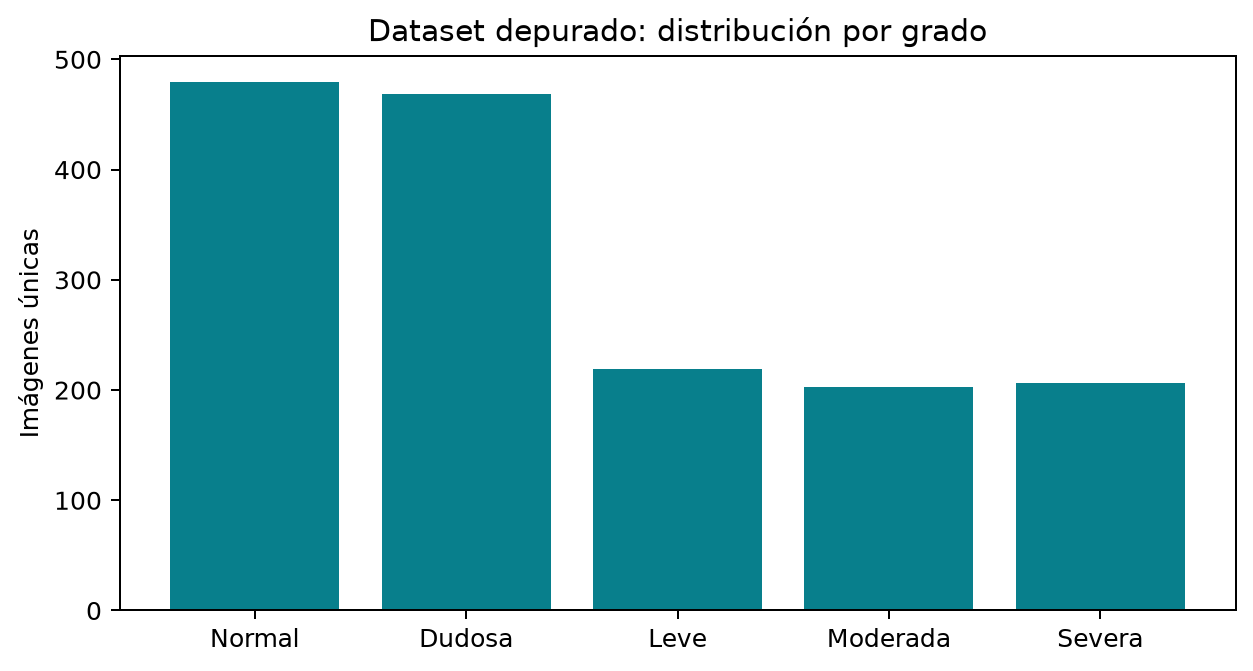

In [ ]:
plt.figure(figsize=(8, 4))

counts = clean.target.value_counts().sort_index()

plt.bar(LABELS, counts, color="#087f8c")

plt.ylabel("Imágenes únicas")

plt.title("Dataset depurado: distribución por grado")

figure("distribucion_clases.png")


## 11. Distribución de resoluciones

Se cuenta cada formato después de depurar. No se eliminan imágenes por ser de un grado o una resolución particular.

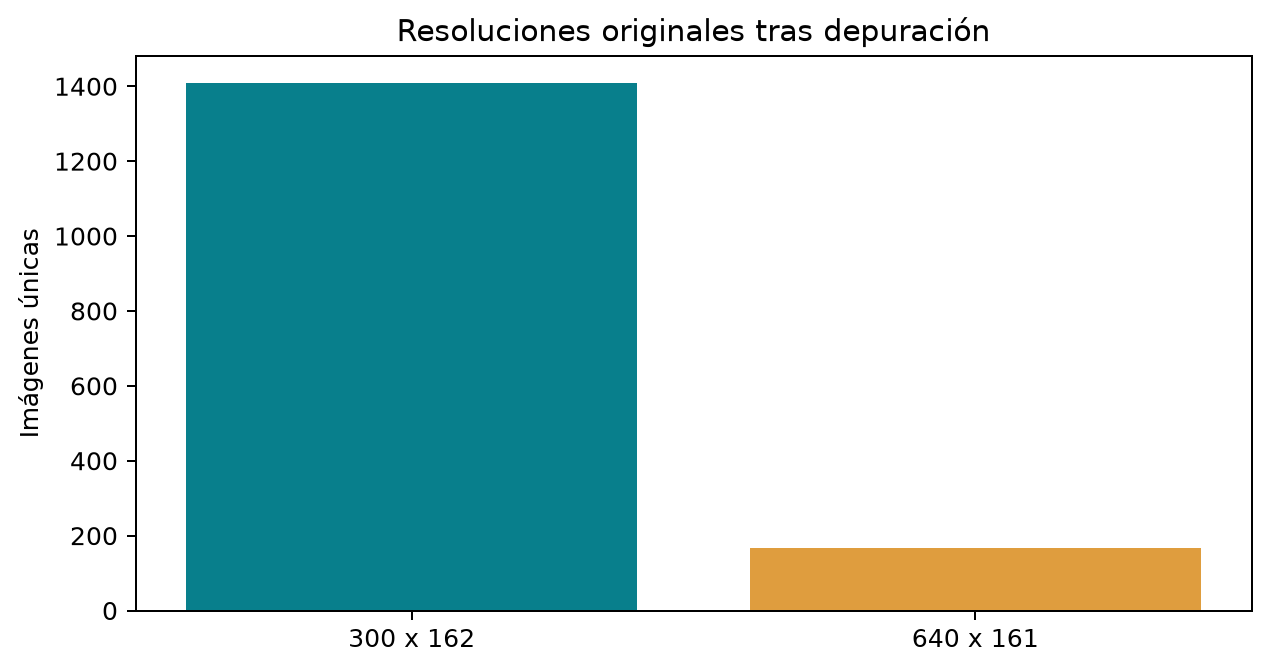

In [ ]:
plt.figure(figsize=(8, 4))

counts = clean.resolution.value_counts().sort_index()

plt.bar(counts.index, counts, color=["#087f8c", "#df9d3e"])

plt.ylabel("Imágenes únicas")

plt.title("Resoluciones originales tras depuración")

figure("eda_resoluciones.png")


## 12. Resolución dentro de cada grado

El mapa de calor muestra el porcentaje de formatos por clase. La asociación entre formato y etiqueta puede actuar como atajo, aun después de estratificar.

{"protocol": "rectangular-masked-v3-2026-11-22", "raw_images": 1650, "unique_eligible_images": 1576, "duplicate_groups": 63, "conflicting_label_groups": 3, "excluded_conflicting_images": 6, "removed_duplicate_copies": 68, "clean_dataset_directory": "data/clean/Training", "clean_images_written": 1576, "raw_images_modified": false, "cross_split_exact_duplicates": 0, "patient_identifiers_available": false, "historical_cross_split_duplicate_groups": 30, "limitation": "Sin identificadores de paciente; no descarta duplicados aproximados, recortes o vistas del mismo paciente."}
split_final  test  train  validation
class_label                         
Dudosa         70    329          70
Leve           33    153          33
Moderada       30    142          31
Normal         73    335          71
Severa         31    144          31


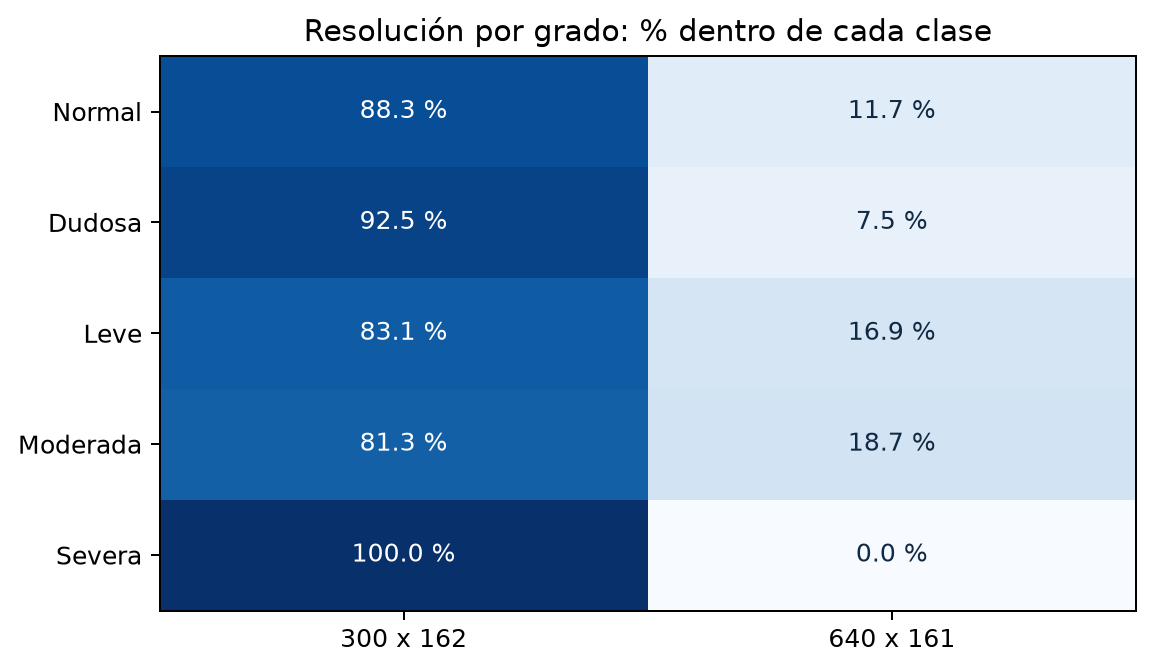

In [ ]:
matrix = pd.crosstab(clean.target, clean.resolution, normalize="index") * 100

fig, ax = plt.subplots(figsize=(7, 4))

ax.imshow(matrix, cmap="Blues", vmin=0, vmax=100, aspect="auto")

ax.set_xticks(range(len(matrix.columns)), matrix.columns)

ax.set_yticks(range(5), LABELS)

for i in range(5):
    for j in range(len(matrix.columns)):
        v = matrix.iloc[i, j]
        ax.text(
            j,
            i,
            f"{v:.1f} %",
            ha="center",
            va="center",
            color="white" if v > 55 else "#102a43",
        )

ax.set_title("Resolución por grado: % dentro de cada clase")

figure("eda_resolucion_por_grado.png")

print(json.dumps(audit, ensure_ascii=False))

print(pd.crosstab(splits.class_label, splits.split_final))


## Interpretación

Hay 1.576 imágenes únicas y particiones de 1.103/236/237. Cero hashes compartidos no garantiza separación por paciente. Los 30 grupos que cruzaban particiones corresponden al protocolo inicial, anterior a v2.